### This notebook is meant to be for data_exploration purposes, 

## To do: get a small dataset on local pc and start from there


In [71]:
import os
import matplotlib.pyplot as plt

In [15]:
mimic_data_path = "/datasets/MIMIC-CXR/files"

In [ ]:
data_dict = {} # data_dict[patient_num][patient_id] = {"text": [list of text file paths], "images": [list of list of image file paths corresponding to each text file]}

for p_num in os.listdir(mimic_data_path):
    data_dict[p_num] = {}
    for patient in os.listdir(os.path.join(mimic_data_path, p_num)):
        data_dict[p_num][patient] = {"text": [], "images": []}
        all_files_of_patient = []
        for patient_files in os.listdir(os.path.join(mimic_data_path, p_num, patient)):
            all_files_of_patient.append(patient_files)
        for file in all_files_of_patient:
            if file.endswith(".txt"):
                data_dict[p_num][patient]["text"].append(os.path.join(mimic_data_path, p_num, patient, file))
                folder_path = file.replace(".txt","")
                folder_path = os.path.join(mimic_data_path, p_num, patient, folder_path)
                if os.path.exists(folder_path):
                    data_dict[p_num][patient]["images"].append([])
                    for image_file in os.listdir(folder_path):
                            data_dict[p_num][patient]["images"][-1].append(os.path.join(folder_path, image_file))
                else:
                     data_dict[p_num][patient]["images"].append([])
            else:
                continue


In [79]:

# Function to print text content and display images for a given patient

def print_data_summary(data_dict, patient_id):
    for text, image in zip(data_dict[patient_id]["text"], data_dict[patient_id]["images"]):
        # read the text file path
        with open(text, 'r') as file:
            content = file.read()
            print(f"{content}")
        if image:
            print("Associated images:")
            for img in image:
                # Open the image
                img_data = plt.imread(img)
                plt.imshow(img_data, cmap='gray')
                plt.show()
        else:
            print("No associated images.")
        print("========"*10)  

                                 FINAL REPORT
 EXAMINATION:  CHEST (PA AND LAT)
 
 INDICATION:  ___F with new onset ascites  // eval for infection
 
 TECHNIQUE:  Chest PA and lateral
 
 COMPARISON:  None.
 
 FINDINGS: 
 
 There is no focal consolidation, pleural effusion or pneumothorax.  Bilateral
 nodular opacities that most likely represent nipple shadows. The
 cardiomediastinal silhouette is normal.  Clips project over the left lung,
 potentially within the breast. The imaged upper abdomen is unremarkable.
 Chronic deformity of the posterior left sixth and seventh ribs are noted.
 
 IMPRESSION: 
 
 No acute cardiopulmonary process.

Associated images:


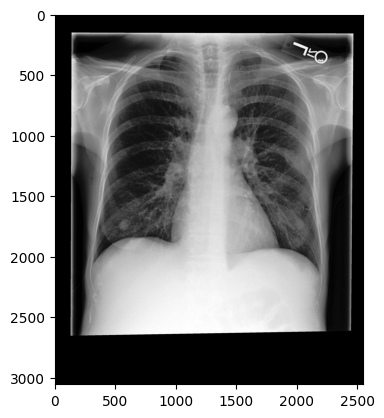

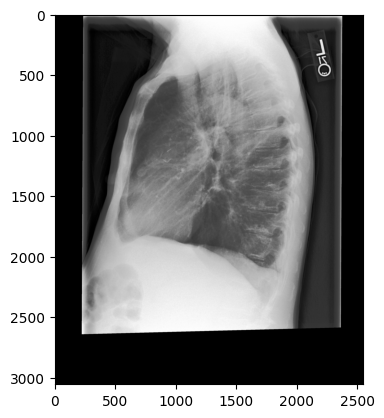

                                 FINAL REPORT
 EXAMINATION:  CHEST (PA AND LAT)
 
 INDICATION:  History: ___F with shortness of breath
 
 TECHNIQUE:  Chest PA and lateral
 
 COMPARISON:  ___
 
 FINDINGS: 
 
 The cardiac, mediastinal and hilar contours are normal. Pulmonary vasculature
 is normal.  Lungs are clear. No pleural effusion or pneumothorax is present.
 Multiple clips are again seen projecting over the left breast.  Remote
 left-sided rib fractures are also re- demonstrated.
 
 IMPRESSION: 
 
 No acute cardiopulmonary abnormality.

No associated images.
                                 FINAL REPORT
 INDICATION:  ___ year old woman with cirrhosis.
 
 TECHNIQUE:  Frontal chest radiographs were obtained with the patient in the
 upright position.
 
 COMPARISON:  Radiographs from ___, ___ and ___.
 
 FINDINGS: 
 
 The lungs are clear of focal consolidation, pleural effusion or pneumothorax. 
 The heart size is normal.  The mediastinal contours are normal. Multiple
 surgical clips p

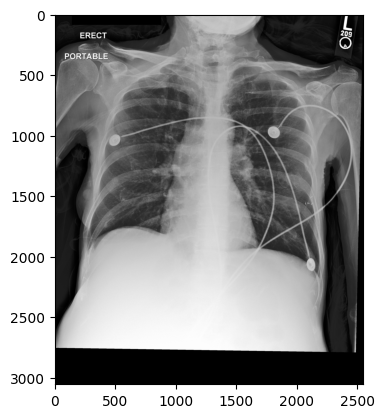

                                 FINAL REPORT
 EXAMINATION:  CHEST (PORTABLE AP)
 
 INDICATION:  ___F with cough  // acute process?
 
 COMPARISON:  Chest radiograph ___
 
 FINDINGS: 
 
 Single frontal view of the chest provided.
 
 There is no focal consolidation, effusion, or pneumothorax. The
 cardiomediastinal silhouette is normal.  Again seen are multiple clips
 projecting over the left breast and remote left-sided rib fractures.  No free
 air below the right hemidiaphragm is seen.
 
 IMPRESSION: 
 
 No acute intrathoracic process.

Associated images:


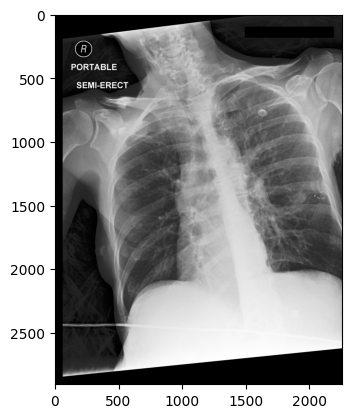

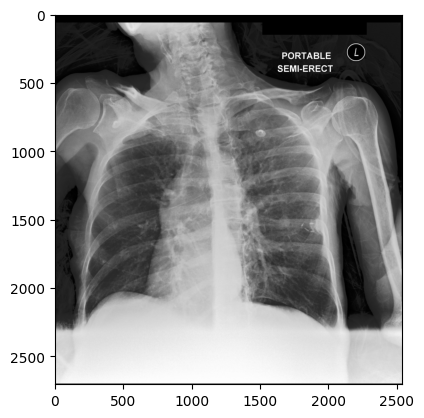

In [80]:
# Example usage

print_data_summary(data_dict["p10"], "p10000032")